# Étape 1 : Regarder les images

In [4]:
!pip install -q "medmnist>=3.0"

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from medmnist import DermaMNIST, INFO

noms = INFO['dermamnist']['label']

train = DermaMNIST(split='train', download=True, size=64, root='/content')
val   = DermaMNIST(split='val',   download=True, size=64, root='/content')
test  = DermaMNIST(split='test',  download=True, size=64, root='/content')

print("Images entrainement :", len(train))
print("Images validation   :", len(val))
print("Images test         :", len(test))

100%|██████████| 100M/100M [02:25<00:00, 687kB/s]


Images entrainement : 7007
Images validation   : 1003
Images test         : 2005


In [6]:
y = train.labels.flatten()
compte = np.bincount(y, minlength=7)

for c in range(7):
    print("Classe", c, ":", compte[c], "images ->", noms[str(c)])

classe_rare = int(np.argmin(compte))
print()
print("LA CLASSE RARE EST :", classe_rare, "-", noms[str(classe_rare)])

Classe 0 : 228 images -> actinic keratoses and intraepithelial carcinoma
Classe 1 : 359 images -> basal cell carcinoma
Classe 2 : 769 images -> benign keratosis-like lesions
Classe 3 : 80 images -> dermatofibroma
Classe 4 : 779 images -> melanoma
Classe 5 : 4693 images -> melanocytic nevi
Classe 6 : 99 images -> vascular lesions

LA CLASSE RARE EST : 3 - dermatofibroma


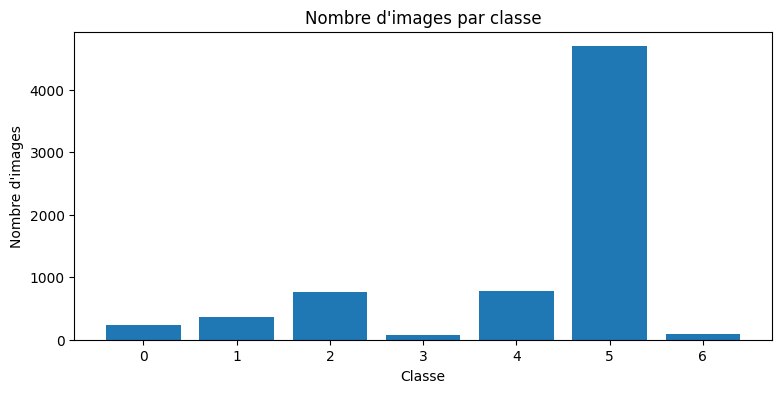

In [7]:
plt.figure(figsize=(9,4))
plt.bar(range(7), compte)
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.title("Nombre d'images par classe")
plt.savefig('/content/classes_train.png', dpi=150)
plt.show()

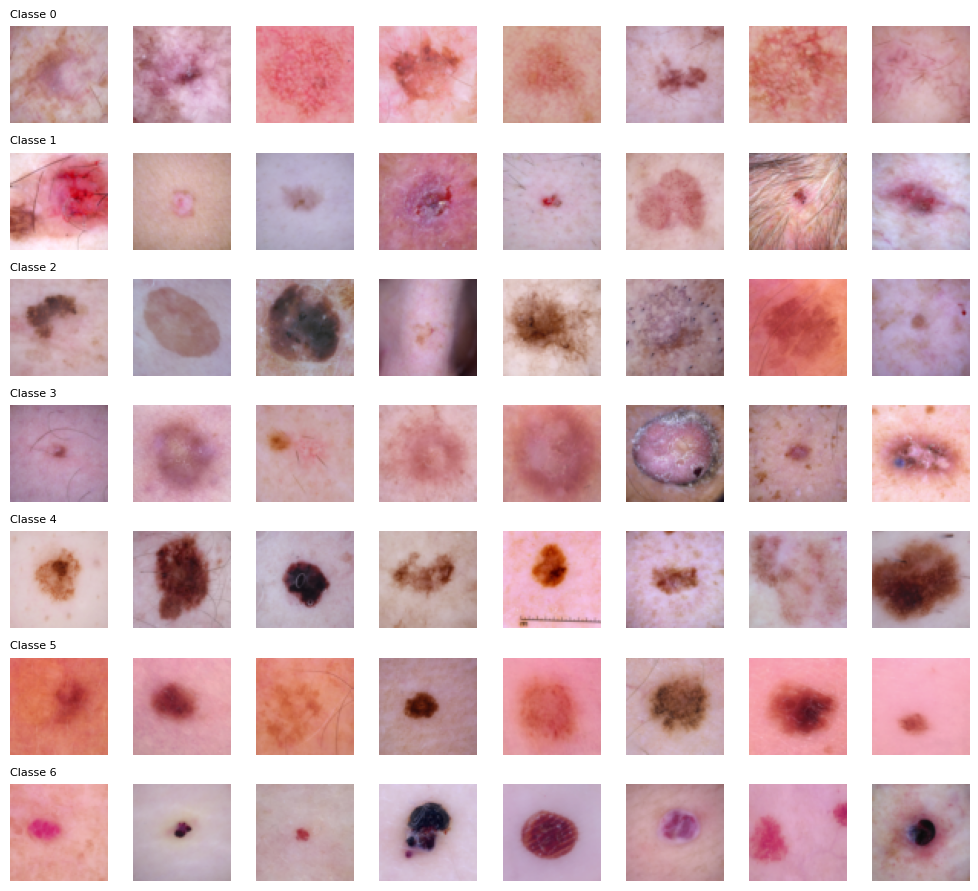

In [8]:
fig, axes = plt.subplots(7, 8, figsize=(10, 9))
for c in range(7):
    indices = np.where(y == c)[0][:8]
    for j, i in enumerate(indices):
        axes[c, j].imshow(train.imgs[i])
        axes[c, j].axis('off')
    axes[c, 0].set_title("Classe " + str(c), fontsize=8, loc='left')
plt.tight_layout()
plt.savefig('/content/exemples_classes.png', dpi=150)
plt.show()

In [9]:
from google.colab import files
files.download('/content/classes_train.png')
files.download('/content/exemples_classes.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Étape 2 : Baseline

In [10]:
import numpy as np
import torch
import torch.nn as nn
from medmnist import DermaMNIST

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Appareil :", device)

def charger(split):
    ds = DermaMNIST(split=split, download=True, size=64, root='/content')
    X = torch.tensor(ds.imgs).permute(0, 3, 1, 2).float() / 255.
    Y = torch.tensor(ds.labels.flatten()).long()
    return X, Y

Xtr, Ytr = charger('train')
Xva, Yva = charger('val')
Xte, Yte = charger('test')
print("Entrainement :", Xtr.shape)
print("Validation   :", Xva.shape)
print("Test         :", Xte.shape)

Appareil : cuda
Entrainement : torch.Size([7007, 3, 64, 64])
Validation   : torch.Size([1003, 3, 64, 64])
Test         : torch.Size([2005, 3, 64, 64])


In [11]:
def creer_modele():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1),   nn.BatchNorm2d(32),  nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1),  nn.BatchNorm2d(64),  nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, 7)
    ).to(device)

print("Modèle prêt")

Modèle prêt


In [12]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, f1_score

def predire(modele, X):
    modele.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X), 256):
            preds.append(modele(X[i:i+256].to(device)).argmax(1).cpu())
    return torch.cat(preds).numpy()

def entrainer(X, Y, epochs=20, seed=0):
    torch.manual_seed(seed)
    modele = creer_modele()
    opt = torch.optim.Adam(modele.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    meilleur, meilleur_etat = -1, None
    for ep in range(epochs):
        modele.train()
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 128):
            idx = perm[i:i+128]
            xb, yb = X[idx].to(device), Y[idx].to(device)
            if torch.rand(1) < 0.5: xb = xb.flip(3)   # miroir gauche-droite
            if torch.rand(1) < 0.5: xb = xb.flip(2)   # miroir haut-bas
            loss = loss_fn(modele(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
        bacc = balanced_accuracy_score(Yva.numpy(), predire(modele, Xva))
        print(f"Epoque {ep+1:2d} | erreur {loss.item():.3f} | score validation {bacc:.3f}")
        if bacc > meilleur:
            meilleur = bacc
            meilleur_etat = {k: v.clone() for k, v in modele.state_dict().items()}
    modele.load_state_dict(meilleur_etat)
    return modele

print("Fonctions prêtes")

Fonctions prêtes


In [13]:
modele_base = entrainer(Xtr, Ytr, epochs=20)

Epoque  1 | erreur 0.788 | score validation 0.259
Epoque  2 | erreur 0.687 | score validation 0.221
Epoque  3 | erreur 0.769 | score validation 0.201
Epoque  4 | erreur 0.602 | score validation 0.355
Epoque  5 | erreur 0.671 | score validation 0.330
Epoque  6 | erreur 0.755 | score validation 0.390
Epoque  7 | erreur 0.542 | score validation 0.396
Epoque  8 | erreur 0.743 | score validation 0.244
Epoque  9 | erreur 0.762 | score validation 0.345
Epoque 10 | erreur 0.516 | score validation 0.226
Epoque 11 | erreur 0.589 | score validation 0.500
Epoque 12 | erreur 0.644 | score validation 0.332
Epoque 13 | erreur 0.539 | score validation 0.460
Epoque 14 | erreur 0.811 | score validation 0.456
Epoque 15 | erreur 0.518 | score validation 0.442
Epoque 16 | erreur 0.501 | score validation 0.439
Epoque 17 | erreur 0.546 | score validation 0.380
Epoque 18 | erreur 0.609 | score validation 0.533
Epoque 19 | erreur 0.571 | score validation 0.489
Epoque 20 | erreur 0.484 | score validation 0.441


In [14]:
def evaluer(modele, nom):
    p = predire(modele, Xte)
    y = Yte.numpy()
    print("Modèle :", nom)
    print("Précision globale      :", round(accuracy_score(y, p), 3))
    print("Précision équilibrée   :", round(balanced_accuracy_score(y, p), 3))
    print("Rappel classe 3 (rare) :", round(recall_score(y, p, labels=[3], average=None)[0], 3))
    print("F1 classe 3 (rare)     :", round(f1_score(y, p, labels=[3], average=None)[0], 3))
    return p

p_base = evaluer(modele_base, "baseline (vraies images seulement)")

Modèle : baseline (vraies images seulement)
Précision globale      : 0.745
Précision équilibrée   : 0.514
Rappel classe 3 (rare) : 0.087
F1 classe 3 (rare)     : 0.148


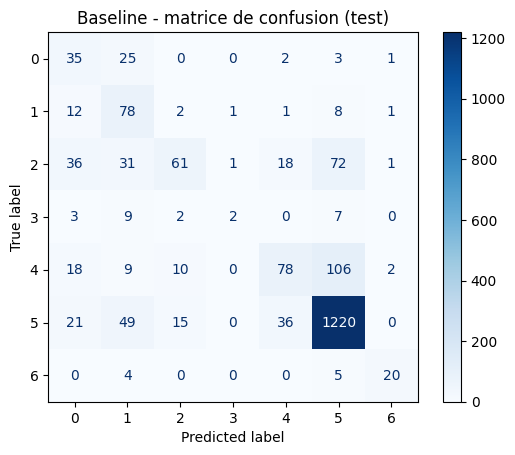

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(Yte.numpy(), p_base, cmap='Blues')
plt.title("Baseline - matrice de confusion (test)")
plt.savefig('/content/confusion_baseline.png', dpi=150)
plt.show()

from google.colab import files
files.download('/content/confusion_baseline.png')

#Étape 3 : le CVAE, premier générateur de fausses images

In [16]:
import torch.nn.functional as F

NB_CLASSES = 7
Z = 64   # nombre de "chiffres secrets" qui résument une image

class CVAE(nn.Module):
    def __init__(self):
        super().__init__()
        # ENCODEUR : image + classe -> chiffres
        self.enc = nn.Sequential(
            nn.Conv2d(3 + NB_CLASSES, 32, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 4, 2, 1),   nn.BatchNorm2d(64),  nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1),  nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2),
            nn.Flatten())
        self.mu     = nn.Linear(256*4*4, Z)
        self.logvar = nn.Linear(256*4*4, Z)
        # DECODEUR : chiffres + classe -> image
        self.fc = nn.Linear(Z + NB_CLASSES, 256*4*4)
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1),  nn.BatchNorm2d(64),  nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1),   nn.BatchNorm2d(32),  nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1),    nn.Sigmoid())

    def encode(self, x, y):
        y_img = F.one_hot(y, NB_CLASSES).float()[:, :, None, None].expand(-1, -1, 64, 64)
        h = self.enc(torch.cat([x, y_img], 1))
        return self.mu(h), self.logvar(h)

    def decode(self, z, y):
        h = self.fc(torch.cat([z, F.one_hot(y, NB_CLASSES).float()], 1))
        return self.dec(h.view(-1, 256, 4, 4))

    def forward(self, x, y):
        mu, logvar = self.encode(x, y)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return self.decode(z, y), mu, logvar

cvae = CVAE().to(device)
print("CVAE prêt")

CVAE prêt


In [17]:
opt_cvae = torch.optim.Adam(cvae.parameters(), lr=1e-3)

# Les classes rares sont montrées plus souvent au modèle
nb_par_classe = torch.bincount(Ytr, minlength=7).float()
poids = (1 / nb_par_classe.sqrt())[Ytr]

EPOQUES = 60
BATCH = 128
pertes_cvae = []

for ep in range(EPOQUES):
    cvae.train()
    ordre = torch.multinomial(poids, len(Xtr), replacement=True)
    total = 0
    for i in range(0, len(Xtr), BATCH):
        idx = ordre[i:i+BATCH]
        xb, yb = Xtr[idx].to(device), Ytr[idx].to(device)
        if torch.rand(1) < 0.5: xb = xb.flip(3)
        rec, mu, logvar = cvae(xb, yb)
        perte_rec = F.binary_cross_entropy(rec, xb, reduction='sum') / len(xb)   # l'image refaite ressemble-t-elle ?
        perte_kl  = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / len(xb)  # les chiffres restent "propres"
        perte = perte_rec + perte_kl
        opt_cvae.zero_grad(); perte.backward(); opt_cvae.step()
        total += perte.item()
    pertes_cvae.append(total)
    if (ep + 1) % 5 == 0:
        print(f"Epoque {ep+1:2d}/{EPOQUES} | perte {total:.0f}")

Epoque  5/60 | perte 406163
Epoque 10/60 | perte 405160
Epoque 15/60 | perte 404526
Epoque 20/60 | perte 403522
Epoque 25/60 | perte 403444
Epoque 30/60 | perte 403848
Epoque 35/60 | perte 403216
Epoque 40/60 | perte 403821
Epoque 45/60 | perte 403437
Epoque 50/60 | perte 403674
Epoque 55/60 | perte 403103
Epoque 60/60 | perte 403367


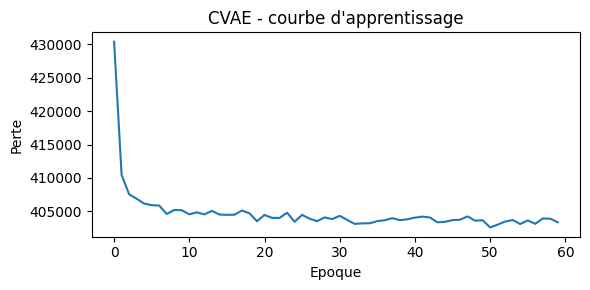

In [18]:
plt.figure(figsize=(6, 3))
plt.plot(pertes_cvae)
plt.xlabel("Epoque"); plt.ylabel("Perte")
plt.title("CVAE - courbe d'apprentissage")
plt.tight_layout()
plt.savefig('/content/cvae_perte.png', dpi=150)
plt.show()

In [19]:
@torch.no_grad()
def generer_cvae(classe, n):
    cvae.eval()
    z = torch.randn(n, Z, device=device)
    y = torch.full((n,), classe, device=device, dtype=torch.long)
    return cvae.decode(z, y).cpu()

print("Fonction prête")

Fonction prête


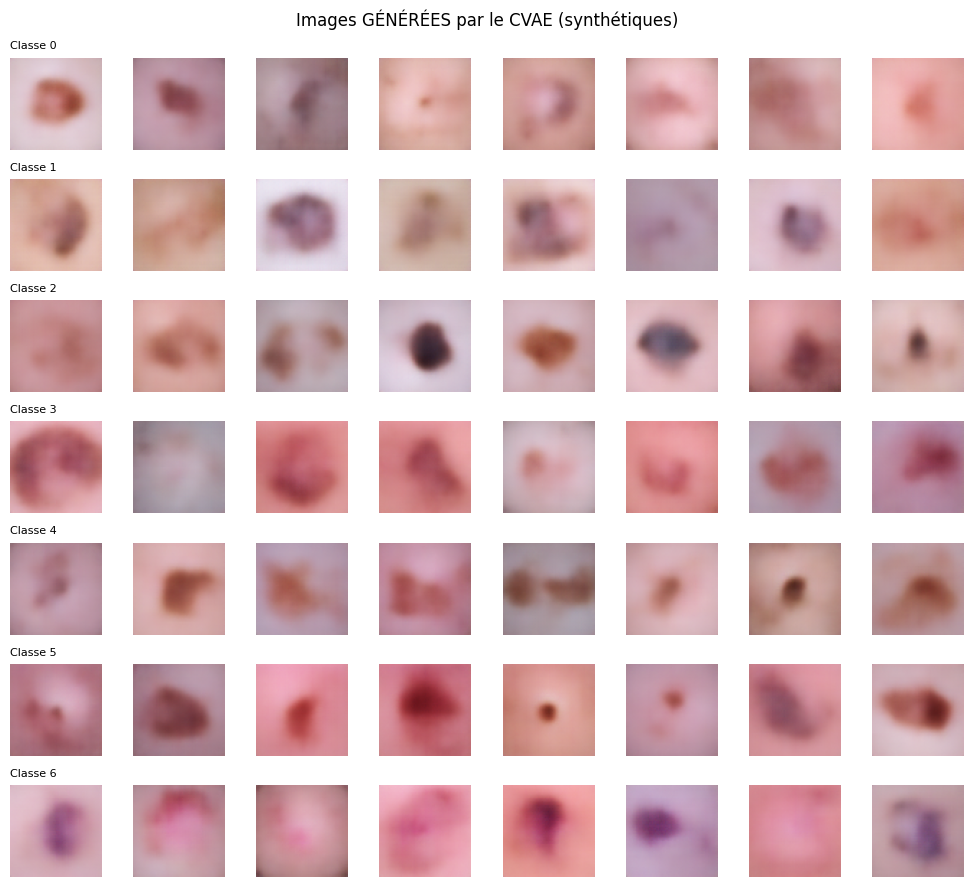

In [20]:
fig, axes = plt.subplots(7, 8, figsize=(10, 9))
for c in range(7):
    imgs = generer_cvae(c, 8)
    for j in range(8):
        axes[c, j].imshow(imgs[j].permute(1, 2, 0))
        axes[c, j].axis('off')
    axes[c, 0].set_title("Classe " + str(c), fontsize=8, loc='left')
plt.suptitle("Images GÉNÉRÉES par le CVAE (synthétiques)")
plt.tight_layout()
plt.savefig('/content/cvae_generees.png', dpi=150)
plt.show()

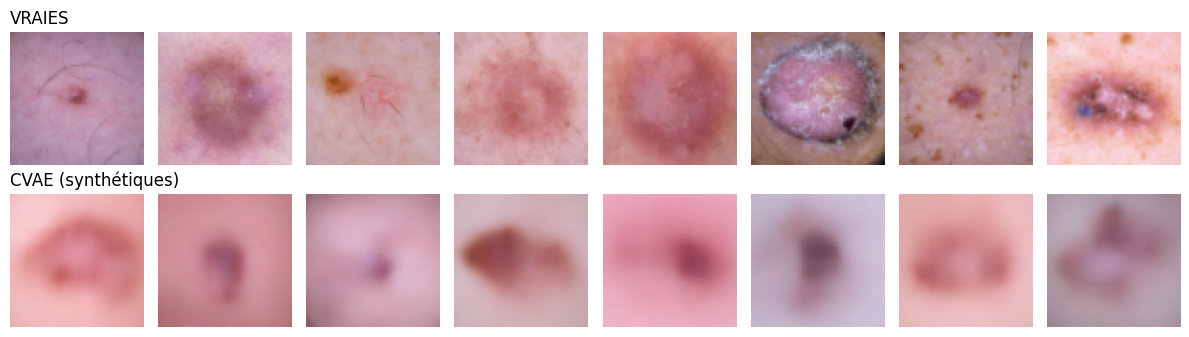

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
vraies = Xtr[Ytr == 3][:8]
fausses = generer_cvae(3, 8)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for j in range(8):
    axes[0, j].imshow(vraies[j].permute(1, 2, 0));  axes[0, j].axis('off')
    axes[1, j].imshow(fausses[j].permute(1, 2, 0)); axes[1, j].axis('off')
axes[0, 0].set_title("VRAIES", loc='left')
axes[1, 0].set_title("CVAE (synthétiques)", loc='left')
plt.tight_layout()
plt.savefig('/content/cvae_classe3.png', dpi=150)
plt.show()

from google.colab import files
for f in ['cvae_perte.png', 'cvae_generees.png', 'cvae_classe3.png']:
    files.download('/content/' + f)

# Étape 4 : GAN conditionnel

In [22]:
from torch.nn.utils import spectral_norm as SN

class Generateur(nn.Module):           # le FAUSSAIRE
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(NB_CLASSES, 50)
        self.fc = nn.Sequential(nn.Linear(Z + 50, 256*4*4), nn.BatchNorm1d(256*4*4), nn.ReLU())
        self.net = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1),  nn.BatchNorm2d(64),  nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1),   nn.BatchNorm2d(32),  nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1),    nn.Tanh())
    def forward(self, z, y):
        h = self.fc(torch.cat([z, self.emb(y)], 1)).view(-1, 256, 4, 4)
        return self.net(h)

class Discriminateur(nn.Module):       # le POLICIER
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            SN(nn.Conv2d(3 + NB_CLASSES, 64, 4, 2, 1)), nn.LeakyReLU(0.2),
            SN(nn.Conv2d(64, 128, 4, 2, 1)),  nn.LeakyReLU(0.2),
            SN(nn.Conv2d(128, 256, 4, 2, 1)), nn.LeakyReLU(0.2),
            SN(nn.Conv2d(256, 512, 4, 2, 1)), nn.LeakyReLU(0.2),
            nn.Flatten(), SN(nn.Linear(512*4*4, 1)))
    def forward(self, x, y):
        y_img = F.one_hot(y, NB_CLASSES).float()[:, :, None, None].expand(-1, -1, 64, 64)
        return self.net(torch.cat([x, y_img], 1))

G = Generateur().to(device)
D = Discriminateur().to(device)
print("Faussaire et policier prêts")

Faussaire et policier prêts


In [23]:
@torch.no_grad()
def generer_gan(classe, n):
    G.eval()
    z = torch.randn(n, Z, device=device)
    y = torch.full((n,), classe, device=device, dtype=torch.long)
    return ((G(z, y) + 1) / 2).clamp(0, 1).cpu()   # on remet les pixels entre 0 et 1

print("Fonction prête")

Fonction prête


Epoque  10/100 | perte policier 87.9 | perte faussaire 32.6
Epoque  20/100 | perte policier 102.8 | perte faussaire 21.2


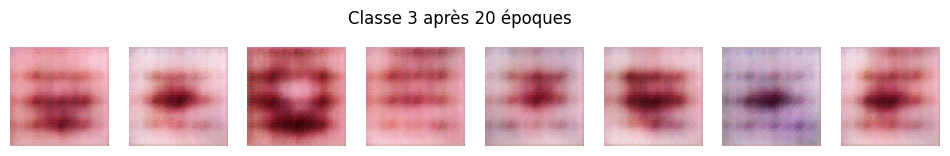

Epoque  30/100 | perte policier 104.7 | perte faussaire 11.6
Epoque  40/100 | perte policier 105.4 | perte faussaire 14.4


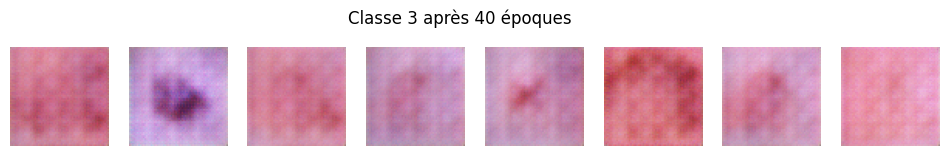

Epoque  50/100 | perte policier 107.3 | perte faussaire 21.9
Epoque  60/100 | perte policier 107.2 | perte faussaire 8.9


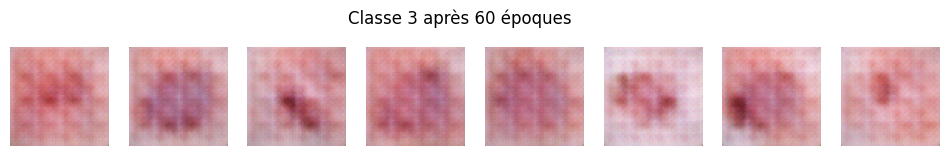

Epoque  70/100 | perte policier 108.3 | perte faussaire 11.1
Epoque  80/100 | perte policier 106.4 | perte faussaire 23.5


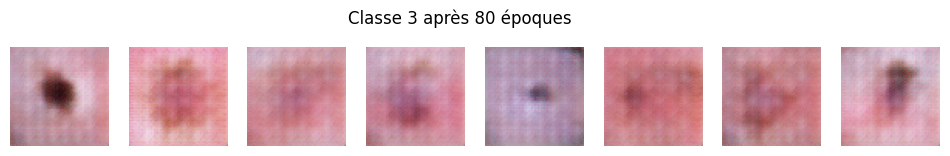

Epoque  90/100 | perte policier 108.7 | perte faussaire 26.7
Epoque 100/100 | perte policier 108.1 | perte faussaire 18.1


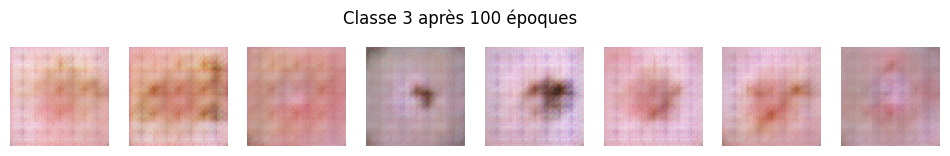

In [24]:
opt_G = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))

EPOQUES_GAN = 100
hist_D, hist_G = [], []

for ep in range(EPOQUES_GAN):
    G.train(); D.train()
    ordre = torch.multinomial(poids, len(Xtr), replacement=True)   # classes rares plus souvent
    sD = sG = 0
    for i in range(0, len(Xtr), BATCH):
        idx = ordre[i:i+BATCH]
        x_vraies = Xtr[idx].to(device) * 2 - 1        # pixels entre -1 et 1
        yb = Ytr[idx].to(device)
        if torch.rand(1) < 0.5: x_vraies = x_vraies.flip(3)
        z = torch.randn(len(yb), Z, device=device)
        x_fausses = G(z, yb)

        # 1) le policier apprend : vraies -> grand score, fausses -> petit score
        perte_D = F.relu(1 - D(x_vraies, yb)).mean() + F.relu(1 + D(x_fausses.detach(), yb)).mean()
        opt_D.zero_grad(); perte_D.backward(); opt_D.step()

        # 2) le faussaire apprend à tromper le policier
        perte_G = -D(x_fausses, yb).mean()
        opt_G.zero_grad(); perte_G.backward(); opt_G.step()

        sD += perte_D.item(); sG += perte_G.item()
    hist_D.append(sD); hist_G.append(sG)

    if (ep + 1) % 10 == 0:
        print(f"Epoque {ep+1:3d}/{EPOQUES_GAN} | perte policier {sD:.1f} | perte faussaire {sG:.1f}")
    if (ep + 1) % 20 == 0:
        imgs = generer_gan(3, 8)
        fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
        for j in range(8):
            axes[j].imshow(imgs[j].permute(1, 2, 0)); axes[j].axis('off')
        plt.suptitle(f"Classe 3 après {ep+1} époques"); plt.show()

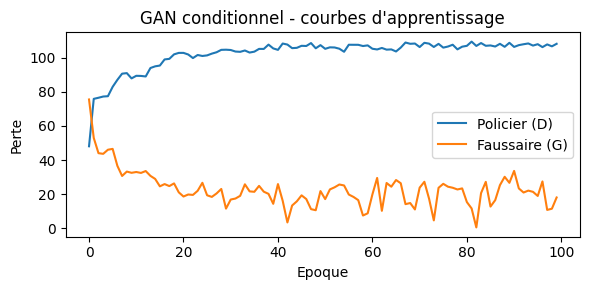

In [28]:
plt.figure(figsize=(6, 3))
plt.plot(hist_D, label="Policier (D)")
plt.plot(hist_G, label="Faussaire (G)")
plt.xlabel("Epoque"); plt.ylabel("Perte"); plt.legend()
plt.title("GAN conditionnel - courbes d'apprentissage")
plt.tight_layout()
plt.savefig('/content/gan_perte.png', dpi=150)
plt.show()

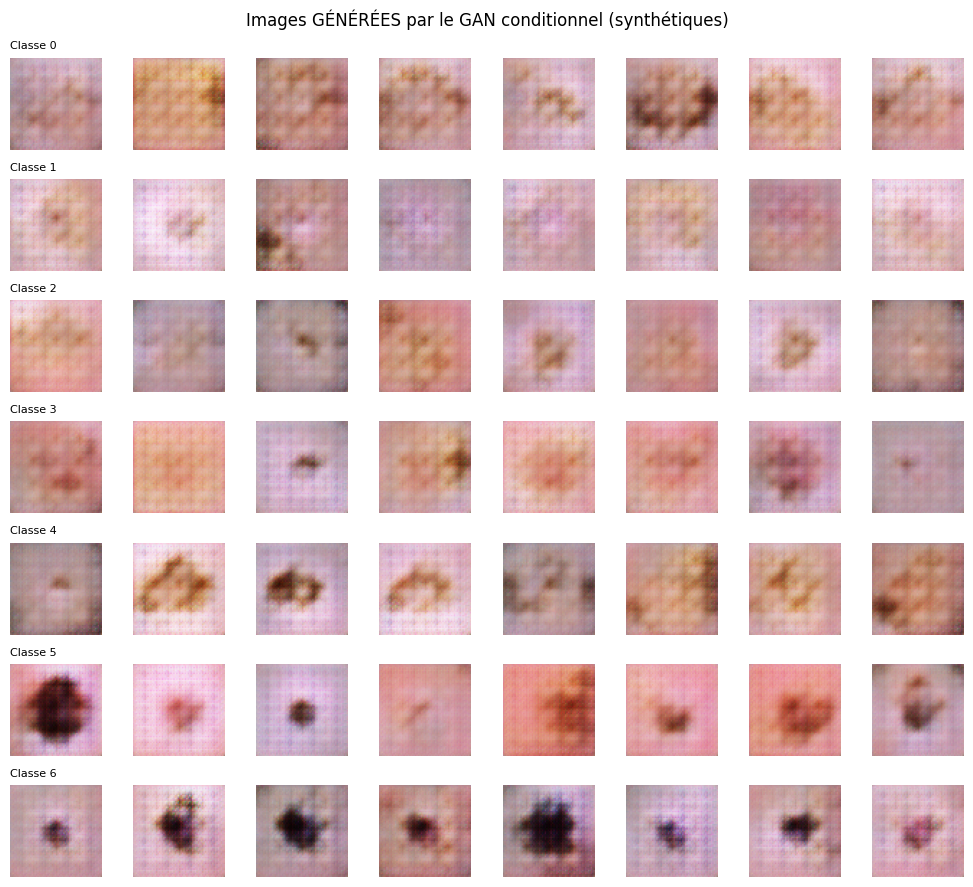

In [29]:
fig, axes = plt.subplots(7, 8, figsize=(10, 9))
for c in range(7):
    imgs = generer_gan(c, 8)
    for j in range(8):
        axes[c, j].imshow(imgs[j].permute(1, 2, 0))
        axes[c, j].axis('off')
    axes[c, 0].set_title("Classe " + str(c), fontsize=8, loc='left')
plt.suptitle("Images GÉNÉRÉES par le GAN conditionnel (synthétiques)")
plt.tight_layout()
plt.savefig('/content/gan_generees.png', dpi=150)
plt.show()

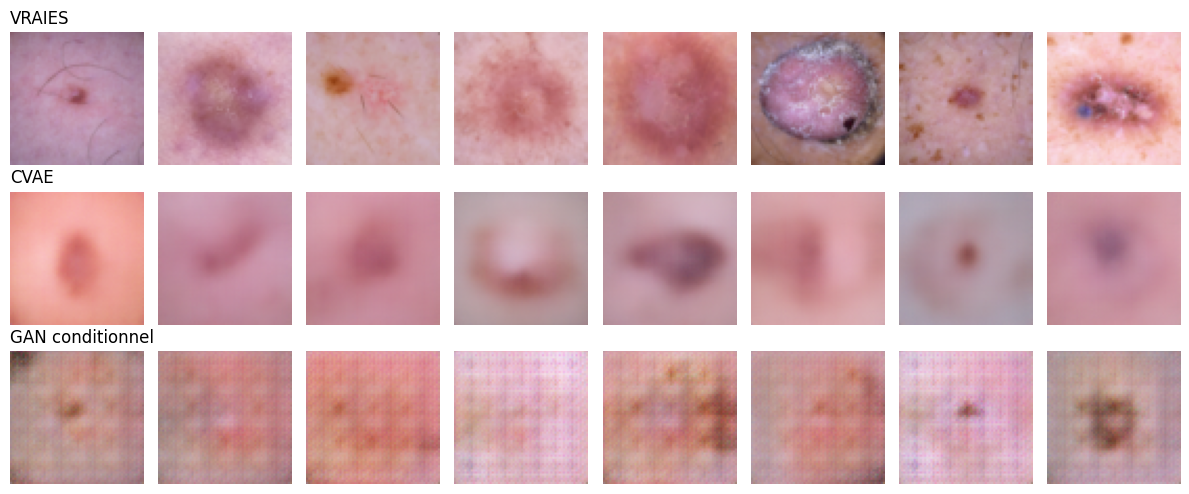

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
vraies  = Xtr[Ytr == 3][:8]
f_cvae  = generer_cvae(3, 8)
f_gan   = generer_gan(3, 8)

fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for j in range(8):
    for r, imgs in enumerate([vraies, f_cvae, f_gan]):
        axes[r, j].imshow(imgs[j].permute(1, 2, 0)); axes[r, j].axis('off')
axes[0, 0].set_title("VRAIES", loc='left')
axes[1, 0].set_title("CVAE", loc='left')
axes[2, 0].set_title("GAN conditionnel", loc='left')
plt.tight_layout()
plt.savefig('/content/comparaison_classe3.png', dpi=150)
plt.show()

from google.colab import files
for f in ['gan_perte.png', 'gan_generees.png', 'comparaison_classe3.png']:
    files.download('/content/' + f)

# Étape 5 : Évaluation

In [31]:
!pip install -q "torchmetrics[image]"

In [32]:
from torchmetrics.image.fid import FrechetInceptionDistance

def calcul_fid(images_a, images_b):
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
    for i in range(0, len(images_a), 100):
        fid.update(images_a[i:i+100].to(device), real=True)
    for i in range(0, len(images_b), 100):
        fid.update(images_b[i:i+100].to(device), real=False)
    return fid.compute().item()

# On fabrique autant de fausses images qu'il y a d'images de test, avec les mêmes proportions de classes
def generer_comme_test(fonction):
    morceaux = []
    for c in range(7):
        n = int((Yte == c).sum())
        morceaux.append(fonction(c, n))
    return torch.cat(morceaux)

fausses_cvae = generer_comme_test(generer_cvae)
fausses_gan  = generer_comme_test(generer_gan)
vraies_train = Xtr[torch.randperm(len(Xtr))[:len(Xte)]]

fid_ref  = calcul_fid(Xte, vraies_train)
fid_cvae = calcul_fid(Xte, fausses_cvae)
fid_gan  = calcul_fid(Xte, fausses_gan)

print("FID référence (vraies vs vraies) :", round(fid_ref, 1), " <- le meilleur possible")
print("FID CVAE                         :", round(fid_cvae, 1))
print("FID GAN conditionnel             :", round(fid_gan, 1))

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 151MB/s]


FID référence (vraies vs vraies) : 13.5  <- le meilleur possible
FID CVAE                         : 212.5
FID GAN conditionnel             : 336.2


In [33]:
def score_classe(fonction, n=200):
    scores = []
    for c in range(7):
        p = predire(modele_base, fonction(c, n))
        scores.append((p == c).mean())
    return np.array(scores)

sc_cvae = score_classe(generer_cvae)
sc_gan  = score_classe(generer_gan)

print("% d'images reconnues dans la classe demandée")
for c in range(7):
    print(f"Classe {c} | CVAE {100*sc_cvae[c]:5.1f} % | GAN {100*sc_gan[c]:5.1f} %")

% d'images reconnues dans la classe demandée
Classe 0 | CVAE   0.0 % | GAN  19.0 %
Classe 1 | CVAE  37.5 % | GAN  81.5 %
Classe 2 | CVAE   9.0 % | GAN  23.0 %
Classe 3 | CVAE   2.0 % | GAN   0.0 %
Classe 4 | CVAE   0.0 % | GAN   0.5 %
Classe 5 | CVAE  96.5 % | GAN  89.0 %
Classe 6 | CVAE  11.0 % | GAN   6.0 %


Distance médiane à l'image d'entraînement la plus proche (classe 3)
  Vraies images de test : 7.6  <- référence
  CVAE                  : 6.54
  GAN                   : 7.46

% d'images suspectes de copie (plus proches que la plus proche image de test)
  CVAE : 4.3 %
  GAN  : 0.0 %


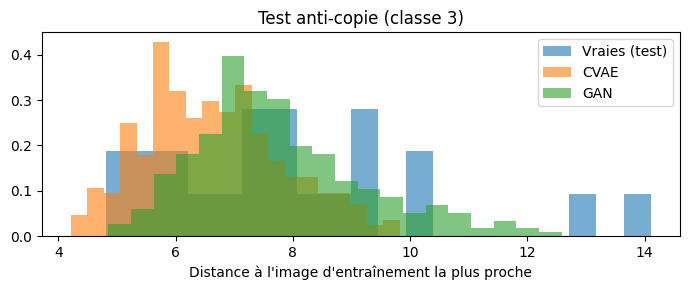

In [34]:
Xtr_plat = Xtr.reshape(len(Xtr), -1).to(device)

def plus_proche(images):
    dists, idxs = [], []
    for i in range(0, len(images), 100):
        lot = images[i:i+100]
        d = torch.cdist(lot.reshape(len(lot), -1).to(device), Xtr_plat)
        m, j = d.min(1)
        dists.append(m.cpu()); idxs.append(j.cpu())
    return torch.cat(dists), torch.cat(idxs)

d_test, _ = plus_proche(Xte[Yte == 3])            # vraies images classe 3 jamais vues
g_cvae = generer_cvae(3, 300); d_cvae, i_cvae = plus_proche(g_cvae)
g_gan  = generer_gan(3, 300);  d_gan,  i_gan  = plus_proche(g_gan)

seuil = d_test.min()
print("Distance médiane à l'image d'entraînement la plus proche (classe 3)")
print("  Vraies images de test :", round(d_test.median().item(), 2), " <- référence")
print("  CVAE                  :", round(d_cvae.median().item(), 2))
print("  GAN                   :", round(d_gan.median().item(), 2))
print()
print("% d'images suspectes de copie (plus proches que la plus proche image de test)")
print("  CVAE :", round(100 * (d_cvae < seuil).float().mean().item(), 1), "%")
print("  GAN  :", round(100 * (d_gan  < seuil).float().mean().item(), 1), "%")

plt.figure(figsize=(7, 3))
plt.hist(d_test.numpy(), bins=20, alpha=0.6, density=True, label="Vraies (test)")
plt.hist(d_cvae.numpy(), bins=20, alpha=0.6, density=True, label="CVAE")
plt.hist(d_gan.numpy(),  bins=20, alpha=0.6, density=True, label="GAN")
plt.xlabel("Distance à l'image d'entraînement la plus proche"); plt.legend()
plt.title("Test anti-copie (classe 3)")
plt.tight_layout(); plt.savefig('/content/anti_copie.png', dpi=150); plt.show()

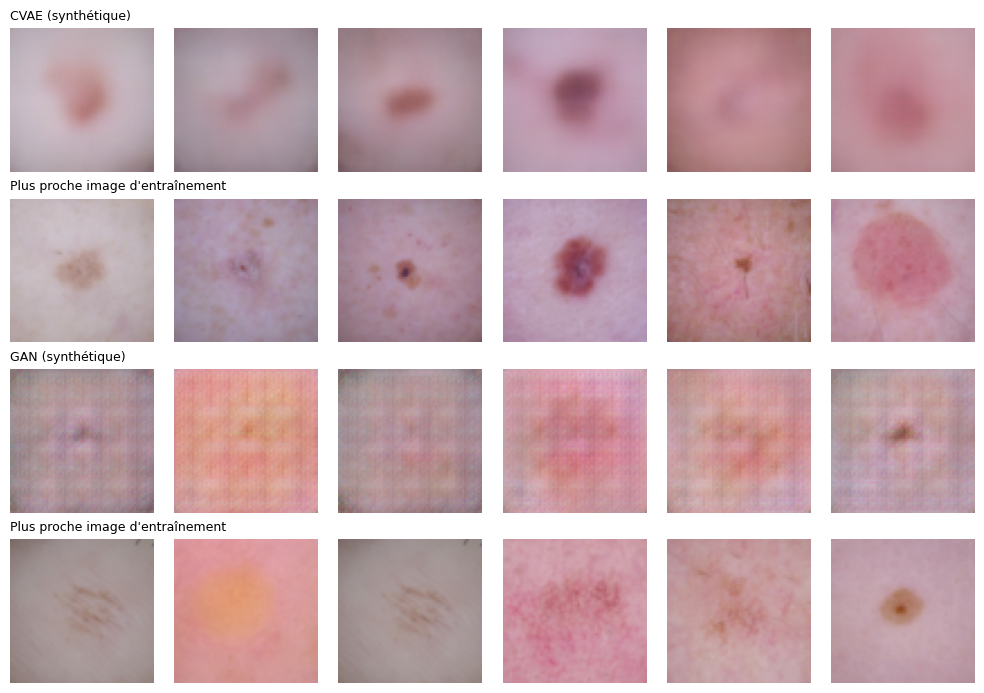

In [35]:
fig, axes = plt.subplots(4, 6, figsize=(10, 7))
for k, (nom, g, d, i) in enumerate([("CVAE", g_cvae, d_cvae, i_cvae), ("GAN", g_gan, d_gan, i_gan)]):
    pires = d.argsort()[:6]
    for j, p in enumerate(pires):
        axes[2*k, j].imshow(g[p].permute(1, 2, 0));          axes[2*k, j].axis('off')
        axes[2*k+1, j].imshow(Xtr[i[p]].permute(1, 2, 0));   axes[2*k+1, j].axis('off')
    axes[2*k, 0].set_title(nom + " (synthétique)", loc='left', fontsize=9)
    axes[2*k+1, 0].set_title("Plus proche image d'entraînement", loc='left', fontsize=9)
plt.tight_layout(); plt.savefig('/content/plus_proches.png', dpi=150); plt.show()

In [36]:
from google.colab import files
for f in ['anti_copie.png', 'plus_proches.png']:
    files.download('/content/' + f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Étape 6 : Augmentation et TSTR

In [37]:
import pandas as pd
import io, contextlib

def generer_par_lots(fonction, classe, n, lot=500):
    return torch.cat([fonction(classe, min(lot, n - i)) for i in range(0, n, lot)])

def scores(modele):
    p = predire(modele, Xte)
    y = Yte.numpy()
    return {
        "precision_globale":    accuracy_score(y, p),
        "precision_equilibree": balanced_accuracy_score(y, p),
        "rappel_classe3":       recall_score(y, p, labels=[3], average=None, zero_division=0)[0],
        "f1_classe3":           f1_score(y, p, labels=[3], average=None, zero_division=0)[0],
    }

def entrainer_silencieux(X, Y, seed):
    with contextlib.redirect_stdout(io.StringIO()):   # cache les 20 lignes d'affichage
        return entrainer(X, Y, epochs=20, seed=seed)

print("Outils prêts")

Outils prêts


In [38]:
N_SYNTH = 500
classe3_cvae = generer_par_lots(generer_cvae, 3, N_SYNTH)
classe3_gan  = generer_par_lots(generer_gan,  3, N_SYNTH)
etiquettes3  = torch.full((N_SYNTH,), 3, dtype=torch.long)

idx3 = torch.where(Ytr == 3)[0]
idx_copies = idx3[torch.randint(len(idx3), (N_SYNTH,))]

jeux = {
    "1. Vraies seulement (baseline)": (Xtr, Ytr),
    "2. + copies vraies classe 3":    (torch.cat([Xtr, Xtr[idx_copies]]), torch.cat([Ytr, Ytr[idx_copies]])),
    "3. + 500 synthetiques CVAE":     (torch.cat([Xtr, classe3_cvae]),    torch.cat([Ytr, etiquettes3])),
    "4. + 500 synthetiques GAN":      (torch.cat([Xtr, classe3_gan]),     torch.cat([Ytr, etiquettes3])),
}

for nom, (X, Y) in jeux.items():
    print(f"{nom:35s} : {len(X)} images, dont {int((Y == 3).sum())} de classe 3")

1. Vraies seulement (baseline)      : 7007 images, dont 80 de classe 3
2. + copies vraies classe 3         : 7507 images, dont 580 de classe 3
3. + 500 synthetiques CVAE          : 7507 images, dont 580 de classe 3
4. + 500 synthetiques GAN           : 7507 images, dont 580 de classe 3


In [39]:
SEEDS = [0, 1, 2]
resultats = []

for nom, (X, Y) in jeux.items():
    for s in SEEDS:
        print(f"En cours : {nom} | essai {s+1}/{len(SEEDS)} ...")
        m = entrainer_silencieux(X, Y, seed=s)
        r = scores(m)
        r["experience"] = nom
        r["essai"] = s
        resultats.append(r)
        print(f"   -> rappel classe 3 = {r['rappel_classe3']:.3f} | précision équilibrée = {r['precision_equilibree']:.3f}")

df = pd.DataFrame(resultats)
df.to_csv('/content/resultats_augmentation.csv', index=False)
print("\nTERMINÉ !")

En cours : 1. Vraies seulement (baseline) | essai 1/3 ...
   -> rappel classe 3 = 0.348 | précision équilibrée = 0.510
En cours : 1. Vraies seulement (baseline) | essai 2/3 ...
   -> rappel classe 3 = 0.000 | précision équilibrée = 0.499
En cours : 1. Vraies seulement (baseline) | essai 3/3 ...
   -> rappel classe 3 = 0.000 | précision équilibrée = 0.499
En cours : 2. + copies vraies classe 3 | essai 1/3 ...
   -> rappel classe 3 = 0.522 | précision équilibrée = 0.585
En cours : 2. + copies vraies classe 3 | essai 2/3 ...
   -> rappel classe 3 = 0.609 | précision équilibrée = 0.598
En cours : 2. + copies vraies classe 3 | essai 3/3 ...
   -> rappel classe 3 = 0.870 | précision équilibrée = 0.512
En cours : 3. + 500 synthetiques CVAE | essai 1/3 ...
   -> rappel classe 3 = 0.304 | précision équilibrée = 0.595
En cours : 3. + 500 synthetiques CVAE | essai 2/3 ...
   -> rappel classe 3 = 0.261 | précision équilibrée = 0.517
En cours : 3. + 500 synthetiques CVAE | essai 3/3 ...
   -> rappe

In [40]:
colonnes = ["precision_globale", "precision_equilibree", "rappel_classe3", "f1_classe3"]
moyenne = df.groupby("experience")[colonnes].mean()
ecart   = df.groupby("experience")[colonnes].std().fillna(0)

tableau = moyenne.round(3).astype(str) + " ± " + ecart.round(3).astype(str)
tableau

,precision_globale,precision_equilibree,rappel_classe3,f1_classe3
experience,,,,
1. Vraies seulement (baseline),0.717 ± 0.045,0.503 ± 0.006,0.116 ± 0.201,0.119 ± 0.205
2. + copies vraies classe 3,0.712 ± 0.018,0.565 ± 0.046,0.667 ± 0.181,0.235 ± 0.073
3. + 500 synthetiques CVAE,0.738 ± 0.012,0.563 ± 0.041,0.261 ± 0.043,0.174 ± 0.072
4. + 500 synthetiques GAN,0.719 ± 0.04,0.48 ± 0.05,0.406 ± 0.375,0.109 ± 0.108


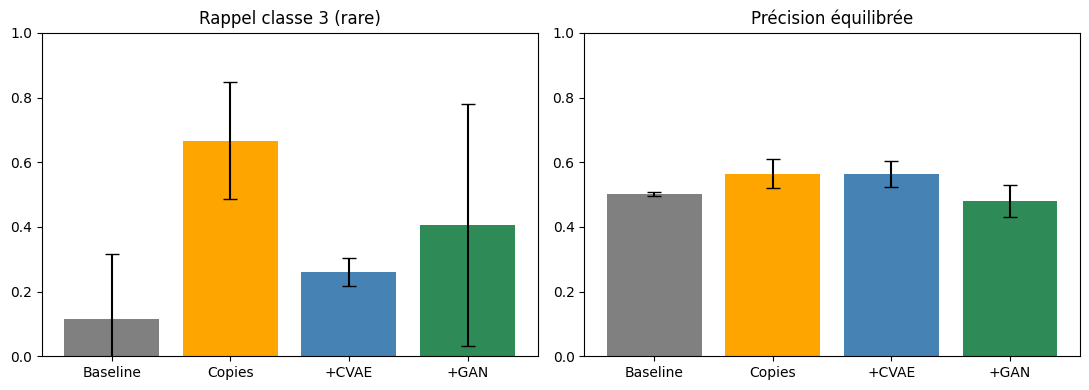

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, titre in [(axes[0], "rappel_classe3", "Rappel classe 3 (rare)"),
                       (axes[1], "precision_equilibree", "Précision équilibrée")]:
    ax.bar(range(len(moyenne)), moyenne[col], yerr=ecart[col], capsize=5,
           color=['gray', 'orange', 'steelblue', 'seagreen'])
    ax.set_xticks(range(len(moyenne)))
    ax.set_xticklabels(["Baseline", "Copies", "+CVAE", "+GAN"])
    ax.set_title(titre); ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('/content/resultats_augmentation.png', dpi=150)
plt.show()

In [42]:
def jeu_100_synthetique(fonction):
    Xs, Ys = [], []
    for c in range(7):
        n = int((Ytr == c).sum())          # mêmes quantités que le vrai jeu
        Xs.append(generer_par_lots(fonction, c, n))
        Ys.append(torch.full((n,), c, dtype=torch.long))
    return torch.cat(Xs), torch.cat(Ys)

tstr = []
r = scores(modele_base); r["experience"] = "TRTR : vraies -> test vraies (référence)"; tstr.append(r)

for nom, fonction in [("CVAE", generer_cvae), ("GAN", generer_gan)]:
    print("En cours : TSTR", nom, "...")
    Xs, Ys = jeu_100_synthetique(fonction)
    m = entrainer_silencieux(Xs, Ys, seed=0)
    r = scores(m); r["experience"] = f"TSTR : {nom} -> test vraies"; tstr.append(r)

df_tstr = pd.DataFrame(tstr).set_index("experience").round(3)
df_tstr.to_csv('/content/resultats_tstr.csv')
df_tstr

En cours : TSTR CVAE ...
En cours : TSTR GAN ...


,precision_globale,precision_equilibree,rappel_classe3,f1_classe3
experience,,,,
TRTR : vraies -> test vraies (référence),0.745,0.514,0.087,0.148
TSTR : CVAE -> test vraies,0.531,0.394,0.000,0.000
TSTR : GAN -> test vraies,0.617,0.234,0.000,0.000


In [43]:
from google.colab import files
for f in ['resultats_augmentation.csv', 'resultats_augmentation.png', 'resultats_tstr.csv']:
    files.download('/content/' + f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Étape 7 : Démo

In [44]:
!pip install -q gradio

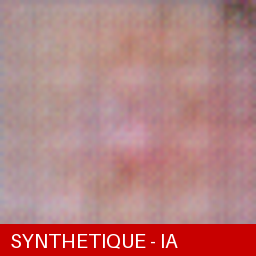

In [45]:
from PIL import Image, ImageDraw, ImageFont

choix_classes = [f"{i} - {noms[str(i)]}" for i in range(7)]

def marquer(img_tensor):
    img = (img_tensor.permute(1, 2, 0).numpy() * 255).astype('uint8')
    img = Image.fromarray(img).resize((256, 256), Image.BICUBIC)   # agrandie pour mieux voir
    d = ImageDraw.Draw(img)
    try:
        police = ImageFont.load_default(size=20)
    except TypeError:
        police = ImageFont.load_default()
    d.rectangle([0, 224, 256, 256], fill=(200, 0, 0))               # bandeau rouge
    d.text((10, 228), "SYNTHETIQUE - IA", fill=(255, 255, 255), font=police)
    return img

def demo_generer(classe_txt, modele_txt, nombre, graine):
    classe = int(classe_txt.split(" - ")[0])
    torch.manual_seed(int(graine))
    fonction = generer_cvae if modele_txt == "CVAE" else generer_gan
    imgs = fonction(classe, int(nombre))
    return [marquer(im) for im in imgs]

# petit test
demo_generer(choix_classes[3], "GAN conditionnel", 1, 0)[0]

In [46]:
import gradio as gr

with gr.Blocks(title="Images dermatologiques synthétiques") as demo:
    gr.Markdown("# 🩺 Générateur d'images de dermoscopie SYNTHÉTIQUES\n"
                "⚠️ Images créées par IA pour la recherche et l'enseignement. "
                "**Ne jamais utiliser pour un diagnostic.**")
    with gr.Row():
        with gr.Column():
            classe = gr.Dropdown(choix_classes, value=choix_classes[3], label="Classe (maladie)")
            modele = gr.Radio(["CVAE", "GAN conditionnel"], value="GAN conditionnel", label="Modèle")
            nombre = gr.Slider(1, 8, value=4, step=1, label="Nombre d'images")
            graine = gr.Number(value=0, precision=0, label="Graine (même graine = mêmes images)")
            bouton = gr.Button("Générer", variant="primary")
        galerie = gr.Gallery(label="Images synthétiques", columns=4, height=420)
    bouton.click(demo_generer, [classe, modele, nombre, graine], galerie)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://552ef46e358c0f9fc1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [47]:
torch.save(cvae.state_dict(), '/content/cvae.pt')
torch.save(G.state_dict(),    '/content/gan_generateur.pt')

from google.colab import files
files.download('/content/cvae.pt')
files.download('/content/gan_generateur.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>